# Project Title

## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

## Data Collection/Sources


In [1]:
#import from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load all the data
house_df= pd.read_csv(url)


In [4]:
# find the float column and make it into a
floats_columns = house_df.select_dtypes(include='float64').columns.tolist()
floats_columns

['Lot Frontage',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area']

In [5]:
target_floats= ['SalePrice'] + floats_columns

In [6]:
house_df_target_floats= house_df[target_floats]

In [7]:
# Columns data types
house_df_target_floats.dtypes.sort_values()


,0
SalePrice,int64
Lot Frontage,float64
Mas Vnr Area,float64
BsmtFin SF 1,float64
BsmtFin SF 2,float64
Bsmt Unf SF,float64
Total Bsmt SF,float64
Bsmt Full Bath,float64
Bsmt Half Bath,float64
Garage Yr Blt,float64


In [8]:
# look at first and last few rows
house_df_target_floats.head()


,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0


In [9]:
# look at the last few rows
house_df_target_floats.tail()

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0
2636,225000,41.0,0.0,870.0,0.0,167.0,1037.0,0.0,0.0,1999.0,2.0,400.0


In [10]:
# look at shape and size

print(house_df_target_floats.shape)
print(house_df_target_floats.size)


(2637, 12)
31644


In [11]:
# display meta data (info)
house_df_target_floats.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   SalePrice       2637 non-null   int64  
 1   Lot Frontage    2188 non-null   float64
 2   Mas Vnr Area    2614 non-null   float64
 3   BsmtFin SF 1    2636 non-null   float64
 4   BsmtFin SF 2    2636 non-null   float64
 5   Bsmt Unf SF     2636 non-null   float64
 6   Total Bsmt SF   2636 non-null   float64
 7   Bsmt Full Bath  2635 non-null   float64
 8   Bsmt Half Bath  2635 non-null   float64
 9   Garage Yr Blt   2490 non-null   float64
 10  Garage Cars     2636 non-null   float64
 11  Garage Area     2636 non-null   float64
dtypes: float64(11), int64(1)
memory usage: 247.3 KB


In [12]:
# display summary statistics
house_df_target_floats.describe()



,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
count,2637.000000,2188.000000,2614.000000,2636.000000,2636.000000,2636.000000,2636.000000,2635.000000,2635.000000,2490.000000,2636.000000,2636.000000
mean,179986.230186,69.166819,101.887911,438.441199,51.068665,555.669196,1045.179059,0.432258,0.058824,1978.185944,1.763278,470.968134
std,78309.251522,23.356779,179.578232,449.602326,172.521803,436.223188,429.686089,0.525239,0.240130,25.452647,0.760576,212.816905
min,12789.000000,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1895.000000,0.000000,0.000000
25%,129500.000000,58.000000,0.000000,0.000000,0.000000,218.000000,792.000000,0.000000,0.000000,1961.000000,1.000000,324.750000
50%,160000.000000,68.000000,0.000000,368.000000,0.000000,464.500000,988.000000,0.000000,0.000000,1979.000000,2.000000,480.000000
75%,213000.000000,80.000000,164.000000,732.000000,0.000000,797.250000,1290.250000,1.000000,0.000000,2002.000000,2.000000,576.000000
max,745000.000000,313.000000,1600.000000,5644.000000,1526.000000,2336.000000,6110.000000,3.000000,2.000000,2207.000000,5.000000,1488.000000


In [13]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [14]:
# look for nulls in target and features
house_df_target_floats.isnull().sum().sort_values(ascending=False)

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2
BsmtFin SF 1,1
Total Bsmt SF,1
BsmtFin SF 2,1
Garage Cars,1
Bsmt Unf SF,1


## Data Cleaning


### Backup 1

In [15]:
# make backup
house_df_target_floats_backup = house_df_target_floats.copy()

In [16]:
# restore from backup
house_df_target_floats = house_df_target_floats_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [17]:
# look for nulls in feature in percentage
house_df_target_floats.isnull().mean() * 100

,0
SalePrice,0.000000
Lot Frontage,17.026925
Mas Vnr Area,0.872203
BsmtFin SF 1,0.037922
BsmtFin SF 2,0.037922
Bsmt Unf SF,0.037922
Total Bsmt SF,0.037922
Bsmt Full Bath,0.075844
Bsmt Half Bath,0.075844
Garage Yr Blt,5.574516


### Impute

In [18]:
# Calculate the median
median_frontage = house_df_target_floats['Lot Frontage'].median()
median_garage_yr = house_df_target_floats['Garage Yr Blt'].median()

print(median_frontage)
print(median_garage_yr)

# Fill nulls with the median
house_df_target_floats['Lot Frontage']= house_df_target_floats['Lot Frontage'].fillna(median_frontage)
house_df_target_floats['Garage Yr Blt']= house_df_target_floats['Garage Yr Blt'].fillna(median_frontage)

#verify there are no nulls
house_df_target_floats.isnull().sum()


68.0
1979.0


,0
SalePrice,0
Lot Frontage,0
Mas Vnr Area,23
BsmtFin SF 1,1
BsmtFin SF 2,1
Bsmt Unf SF,1
Total Bsmt SF,1
Bsmt Full Bath,2
Bsmt Half Bath,2
Garage Yr Blt,0


In [19]:
print(house_df_target_floats['Lot Frontage'].median())
print(house_df_target_floats['Garage Yr Blt'].median())

68.0
1977.0


In [23]:
house_df_target_floats.isnull().sum() * 100000

,0
SalePrice,0
Lot Frontage,0
Mas Vnr Area,2300000
BsmtFin SF 1,100000
BsmtFin SF 2,100000
Bsmt Unf SF,100000
Total Bsmt SF,100000
Bsmt Full Bath,200000
Bsmt Half Bath,200000
Garage Yr Blt,0


In [29]:
# drop the nulls values in features
house_df_target_floats = house_df_target_floats.dropna(subset=['Mas Vnr Area',
'BsmtFin SF 1',
'BsmtFin SF 2',
'Bsmt Unf SF',
'Total Bsmt SF',
'Bsmt Full Bath',
'Garage Cars',
'Garage Area',
'Bsmt Half Bath'])

In [30]:
#check that null are removed from features
house_df_target_floats.isnull().sum()

,0
SalePrice,0
Lot Frontage,0
Mas Vnr Area,0
BsmtFin SF 1,0
BsmtFin SF 2,0
Bsmt Unf SF,0
Total Bsmt SF,0
Bsmt Full Bath,0
Bsmt Half Bath,0
Garage Yr Blt,0


## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

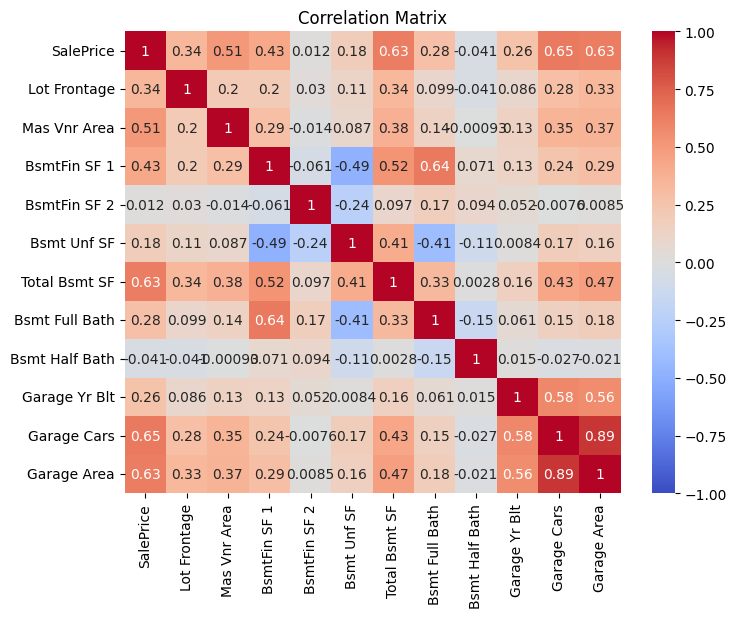

In [33]:
# Calcualte & display  correlation matrix, check if feature corelated with target
plt.figure(figsize=(8, 6))
sns.heatmap(house_df_target_floats.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()

In [34]:
# Calculate a correlation matrix for features & features
features_df = house_df_target_floats.drop(columns=['SalePrice'])
features_corr = features_df.corr()

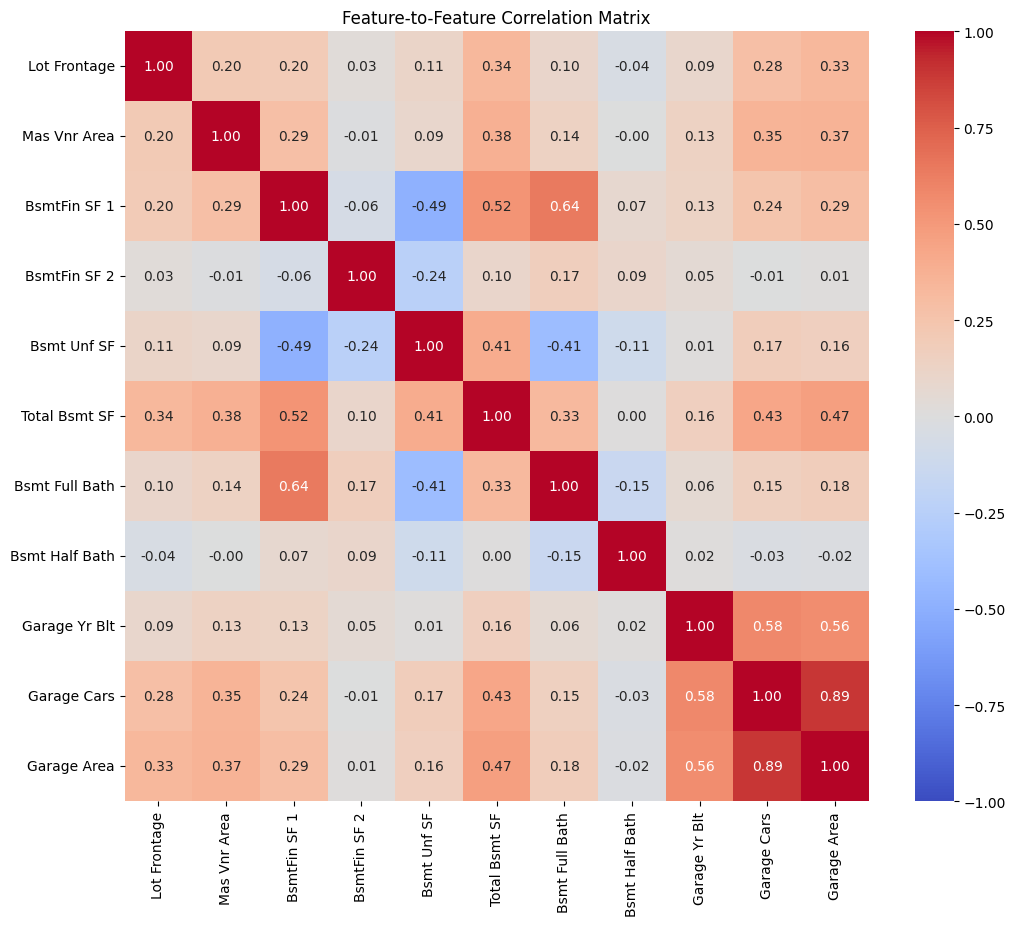

In [35]:
# Display the matrix, check if features are correlated with each other
plt.figure(figsize=(12, 10))      # bigger, since there are more columns
sns.heatmap(features_corr,
            annot=True,
            fmt='.2f',            # round numbers to 2 decimals so they fit
            cmap='coolwarm',
            center=0,
            vmin=-1, vmax=1)
plt.title('Feature-to-Feature Correlation Matrix')
plt.show()

## Processing



## Data Visualization/Communication of Results
